# Predicting Student Performance with Multiple Linear Regression


## Loading Libraries & Data

In [1]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
TARGET = "Performance Index"

In [2]:
# Read Dataset
df = pd.read_csv("/content/Student_Performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [3]:
# Dataset Information and Data Types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [4]:
# Check for Missing Values
df.isna().sum() / df.shape[0]

,0
Hours Studied,0.0
Previous Scores,0.0
Extracurricular Activities,0.0
Sleep Hours,0.0
Sample Question Papers Practiced,0.0
Performance Index,0.0


In [5]:
# Dataset Dimensions
df.shape

(10000, 6)

In [6]:
# Check for Duplicated Rows
df.duplicated().any()

np.True_

In [7]:
# Duplicated Data Check Output is True
duplicates = df.duplicated().sum()
print(f"{duplicates} duplicated rows")

127 duplicated rows


there is a possibility to have a duplicated rows in our 6 column dataset so we will let the duplicated data be

In [8]:
# Dataset Statistics
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [9]:
# Unique Values in Dataset
for col in df.columns:
    unique_values = df[col].unique()
    print(f"Column '{col}' ({len(unique_values)} unique values):")
    print(unique_values)
    print("-" * 40)

Column 'Hours Studied' (9 unique values):
[7 4 8 5 3 6 2 1 9]
----------------------------------------
Column 'Previous Scores' (60 unique values):
[99 82 51 52 75 78 73 45 77 89 91 79 47 72 83 54 96 74 85 61 62 84 94 90
 44 70 67 97 59 55 68 63 46 76 43 81 93 98 48 92 64 88 60 87 40 69 80 95
 49 50 53 71 56 58 66 65 57 41 42 86]
----------------------------------------
Column 'Extracurricular Activities' (2 unique values):
['Yes' 'No']
----------------------------------------
Column 'Sleep Hours' (6 unique values):
[9 4 7 5 8 6]
----------------------------------------
Column 'Sample Question Papers Practiced' (10 unique values):
[1 2 5 6 0 8 3 4 9 7]
----------------------------------------
Column 'Performance Index' (91 unique values):
[ 91.  65.  45.  36.  66.  61.  63.  42.  69.  84.  73.  27.  33.  68.
  43.  67.  70.  30.  71.  85.  57.  35.  49.  83.  74.  39.  58.  47.
  60.  32.  64.  54.  17.  53.  75.  52.  78.  38.  98.  87.  41.  81.
  15.  88.  95.  29.  21.  76.  25.  3

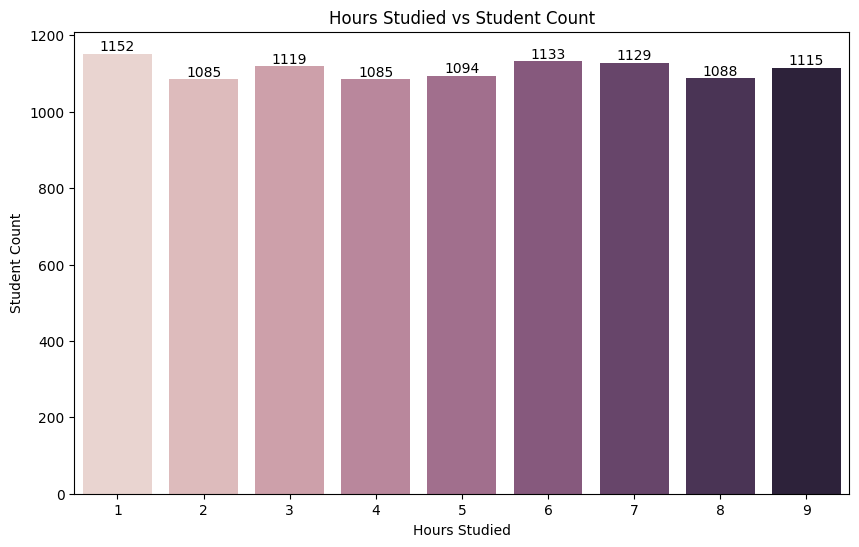

In [10]:
# Hours Studied vs Student Count
plt.figure(figsize=(10, 6))
ax = sns.countplot(x='Hours Studied', data=df, hue='Hours Studied', legend=False)
for container in ax.containers:
    ax.bar_label(container)

plt.title('Hours Studied vs Student Count')
plt.xlabel('Hours Studied')
plt.ylabel('Student Count')
plt.show()

we can see that Hours Studied is almost uniformly distributed

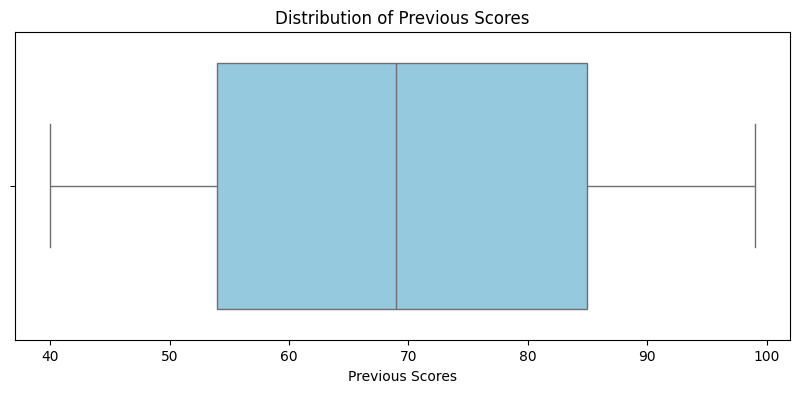

In [11]:
# Previous Score Distribution
plt.figure(figsize=(10, 4))
sns.boxplot(x='Previous Scores', data=df, color='skyblue')
plt.title('Distribution of Previous Scores')
plt.xlabel('Previous Scores')
plt.show()

we can see that half of the students scored above 69

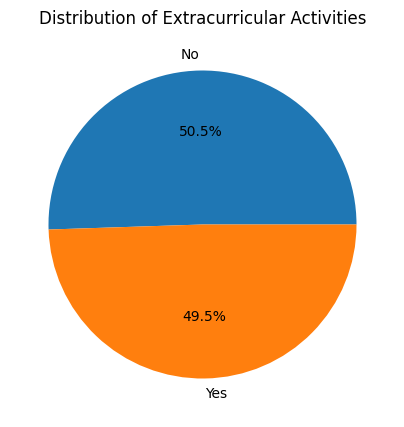

In [12]:
# Extracurricular Activities Distribution
plt.figure(figsize=(5, 5))
activity_counts = df["Extracurricular Activities"].value_counts()
plt.pie(activity_counts, labels=activity_counts.index, autopct='%1.1f%%')
plt.title('Distribution of Extracurricular Activities')
plt.show()

we can see that the distribution is almost even where more students join extracurricular activities than the students who does not

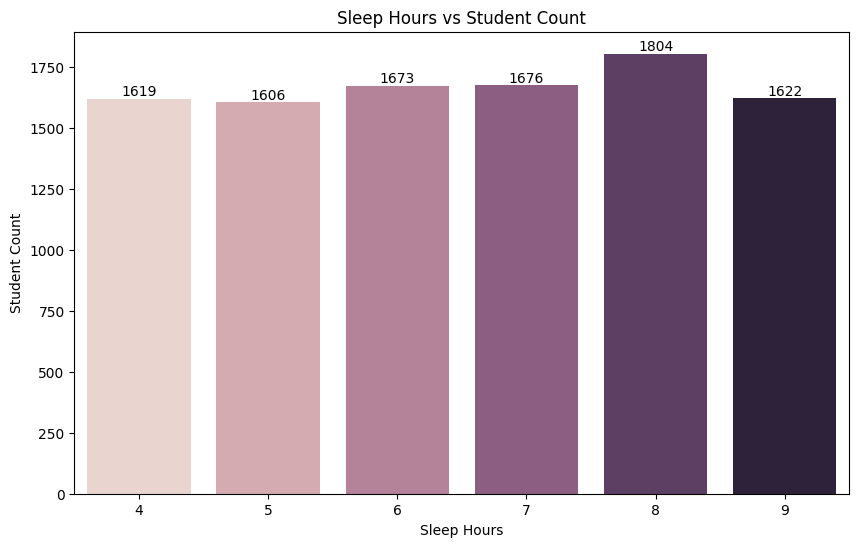

In [13]:
# Sleep Hours vs Student Count
plt.figure(figsize=(10, 6))
ax = sns.countplot(x='Sleep Hours', data=df, hue='Sleep Hours', legend=False)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Sleep Hours vs Student Count')
plt.xlabel('Sleep Hours')
plt.ylabel('Student Count')
plt.show()

we can see that 8 hours of sleep is the mode

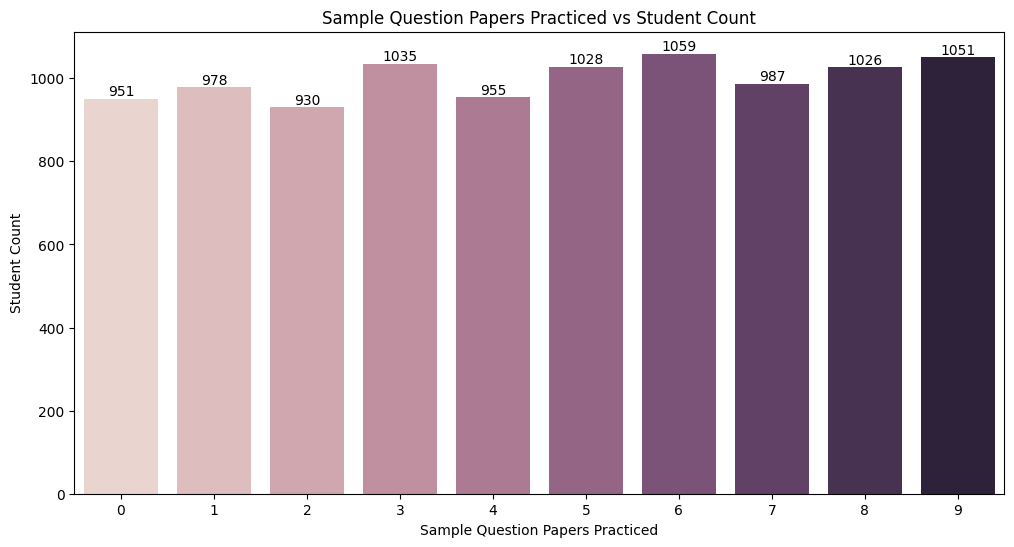

In [14]:
# Sample Question Papers Practiced vs Student Count
plt.figure(figsize=(12, 6))
ax = sns.countplot(x='Sample Question Papers Practiced', data=df, hue='Sample Question Papers Practiced', legend=False)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Sample Question Papers Practiced vs Student Count')
plt.xlabel('Sample Question Papers Practiced')
plt.ylabel('Student Count')
plt.show()

we can see that the sample question papers practiced is almost uniformly distributed to students

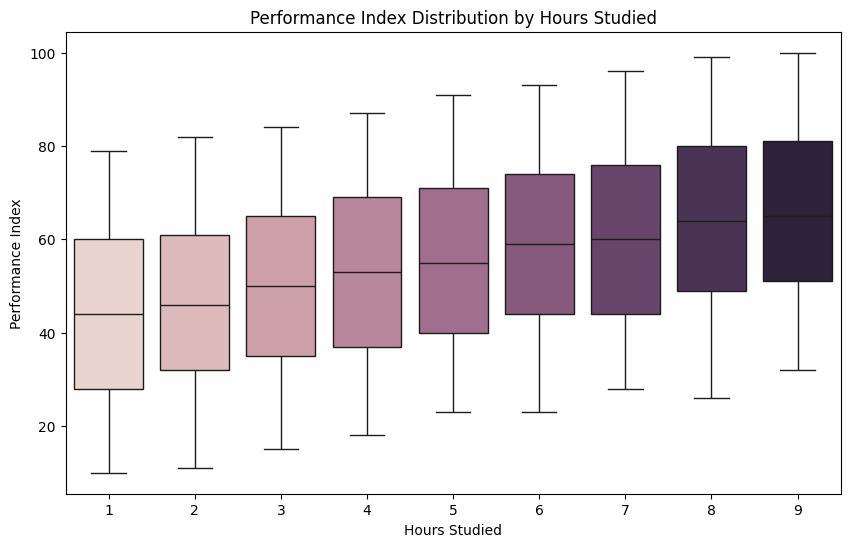

In [15]:
# Hours Studied and Performance Index distribution
plt.figure(figsize=(10, 6))
sns.boxplot(x="Hours Studied", y=TARGET, data=df, hue="Hours Studied", legend=False)
plt.title('Performance Index Distribution by Hours Studied')
plt.xlabel('Hours Studied')
plt.ylabel('Performance Index')
plt.show()

we can conclude that the more hours the student study, the higher also are their performance index

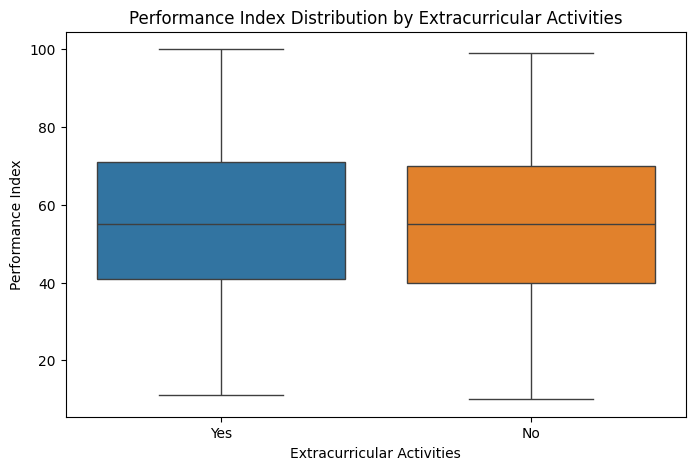

In [16]:
# Performance Index vs Extracurricular Activities
plt.figure(figsize=(8, 5))
sns.boxplot(x="Extracurricular Activities", y=TARGET, data=df, hue="Extracurricular Activities", legend=False)
plt.title('Performance Index Distribution by Extracurricular Activities')
plt.xlabel('Extracurricular Activities')
plt.ylabel('Performance Index')
plt.show()

joining or not joining extracurricular activities have low correlation to student's performance index

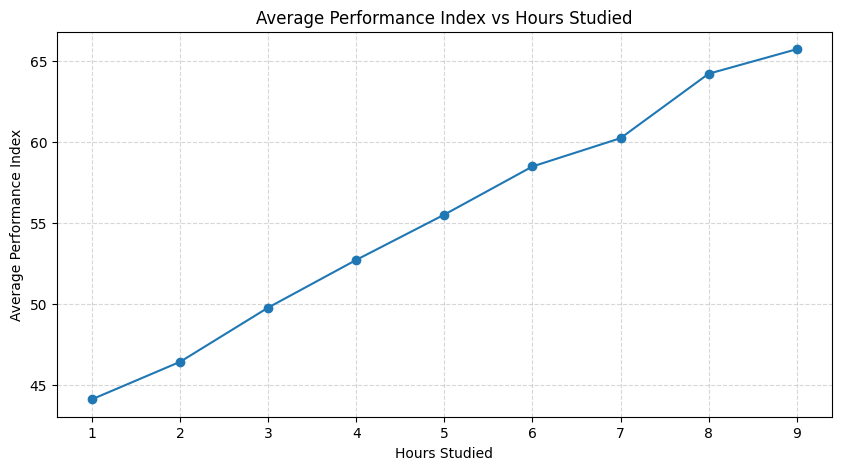

In [17]:
# Average Performance Index vs Hours Studied
avg_performance_by_hours = df.groupby('Hours Studied')[TARGET].mean()

plt.figure(figsize=(10, 5))
plt.plot(avg_performance_by_hours.index, avg_performance_by_hours.values, marker='o')
plt.title('Average Performance Index vs Hours Studied')
plt.xlabel('Hours Studied')
plt.ylabel('Average Performance Index')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

the average performance index rises almost linearly as student's hours studied



### Heatmap of Correlation

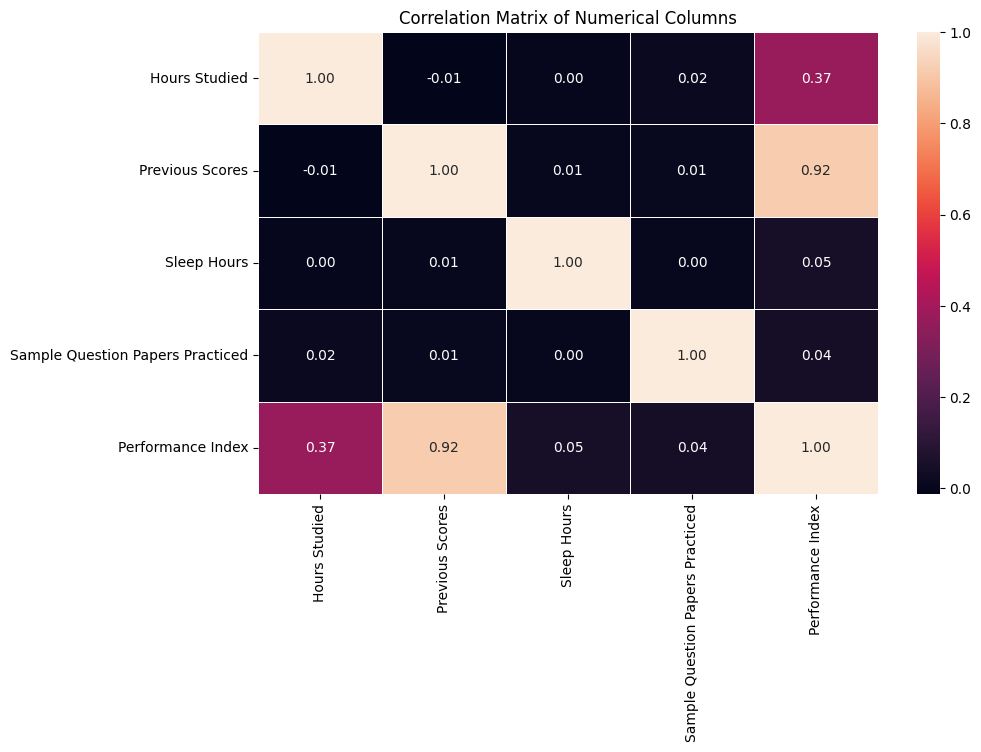

In [18]:
# Correlation Matrix
numeric_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Numerical Columns')
plt.show()

   - previous scores has a very strong positive correlation with performance index (0.92)
   - hours studied has a moderate one (0.37); sleep hours (0.05) and sample question papers practiced (0.04) almost having no correlation


##  Modeling

In [19]:
# Encode Extracurricular Activities (No = 0, Yes = 1)
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

df["Extracurricular Activities"] =  encoder.fit_transform(df["Extracurricular Activities"])
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [20]:
# Split Data and Label the Target
X = df.drop(columns = TARGET)
y = df[TARGET]

In [21]:
# Split data into Training and test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

# Split Data Shape
print("X_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

X_train shape:  (8000, 5)
y_train shape:  (8000,)
X_test shape:  (2000, 5)
y_test shape:  (2000,)


In [22]:
# Linear Regression Model
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

## Evaluate Score

In [23]:
# Calculate Model Score

model.score(X_train, y_train)

0.9886898790682355

In [24]:
# Real Values vs Predicted Values
y_pred = np.round(model.predict(X_test), decimals = 1)

pd.DataFrame({"Actual Performance" : y_test, "Predicted Performance" : y_pred})

,Actual Performance,Predicted Performance
6252,51.0,54.7
4684,20.0,22.6
1731,46.0,47.9
4742,28.0,31.3
4521,41.0,43.0
...,...,...
6412,45.0,46.9
8285,66.0,62.7
7853,16.0,16.8
1095,65.0,63.3


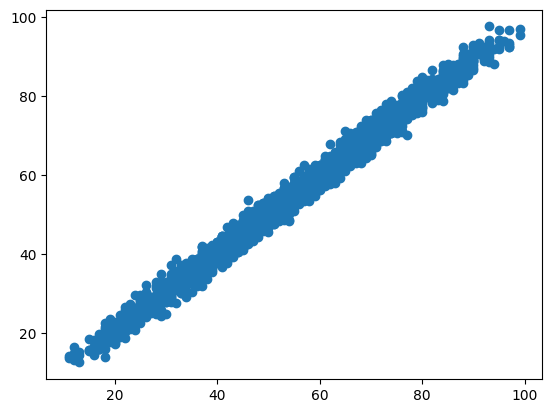

In [25]:
# Create Scatter Plot to see the Distribution

plt.scatter(y_test, y_pred)
plt.show()

In [26]:
# See Mean Absolute Error
from sklearn.metrics import mean_absolute_error

mean_absolute_error(y_test, y_pred)

1.612

In [27]:
# See R2 Score
from sklearn.metrics import r2_score

r2_score(y_test, y_pred)

0.9889704960519785

In [28]:
# See Multiple Regression Coefficients Values

model.coef_

array([2.85248393, 1.0169882 , 0.60861668, 0.47694148, 0.19183144])

In [29]:
# See Y Intercept

model.intercept_

np.float64(-33.92194621555638)

**Final Equation of our multiple linear regression model is :**
   - 2.85 × Hours Studied + 1.02 × Previous Scores + 0.61 × Extracurricular Activities + 0.48 × Sleep Hours + 0.19 × Sample Question Papers Practiced - 33.92

## Model Comparison with Cross-Validation

Here, we will compare and find reasons or change the model based on the model quality to predict our data

In [30]:
# Compare Models with 5-Fold Cross-Validation
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Settings used by every model
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ("r2", "neg_mean_absolute_error")

# Empty table, one row will be added for each model
results = pd.DataFrame(columns=["CV R2 (mean)", "CV R2 (std)", "CV MAE", "Test R2", "Test MAE", "Test RMSE"])
results

,CV R2 (mean),CV R2 (std),CV MAE,Test R2,Test MAE,Test RMSE


In [31]:
# 1. Baseline (always predicts the average Performance Index)
baseline = DummyRegressor(strategy="mean")
baseline_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring=scoring)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

results.loc["Baseline (mean)"] = [
    baseline_cv["test_r2"].mean(),
    baseline_cv["test_r2"].std(),
    -baseline_cv["test_neg_mean_absolute_error"].mean(),
    r2_score(y_test, baseline_pred),
    mean_absolute_error(y_test, baseline_pred),
    np.sqrt(mean_squared_error(y_test, baseline_pred)),
]

In [32]:
# 2. Linear Regression
linear = LinearRegression()
linear_cv = cross_validate(linear, X_train, y_train, cv=cv, scoring=scoring)
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)

results.loc["Linear Regression"] = [
    linear_cv["test_r2"].mean(),
    linear_cv["test_r2"].std(),
    -linear_cv["test_neg_mean_absolute_error"].mean(),
    r2_score(y_test, linear_pred),
    mean_absolute_error(y_test, linear_pred),
    np.sqrt(mean_squared_error(y_test, linear_pred)),
]

In [33]:
# 3. Ridge (scale the features first, then fit)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge_cv = cross_validate(ridge, X_train, y_train, cv=cv, scoring=scoring)
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

results.loc["Ridge"] = [
    ridge_cv["test_r2"].mean(),
    ridge_cv["test_r2"].std(),
    -ridge_cv["test_neg_mean_absolute_error"].mean(),
    r2_score(y_test, ridge_pred),
    mean_absolute_error(y_test, ridge_pred),
    np.sqrt(mean_squared_error(y_test, ridge_pred)),
]

In [34]:
# 4. Lasso (scale the features first, then fit)
lasso = make_pipeline(StandardScaler(), Lasso(alpha=0.01))
lasso_cv = cross_validate(lasso, X_train, y_train, cv=cv, scoring=scoring)
lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

results.loc["Lasso"] = [
    lasso_cv["test_r2"].mean(),
    lasso_cv["test_r2"].std(),
    -lasso_cv["test_neg_mean_absolute_error"].mean(),
    r2_score(y_test, lasso_pred),
    mean_absolute_error(y_test, lasso_pred),
    np.sqrt(mean_squared_error(y_test, lasso_pred)),
]

In [35]:
# 5. Random Forest
forest = RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)
forest_cv = cross_validate(forest, X_train, y_train, cv=cv, scoring=scoring)
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)

results.loc["Random Forest"] = [
    forest_cv["test_r2"].mean(),
    forest_cv["test_r2"].std(),
    -forest_cv["test_neg_mean_absolute_error"].mean(),
    r2_score(y_test, forest_pred),
    mean_absolute_error(y_test, forest_pred),
    np.sqrt(mean_squared_error(y_test, forest_pred)),
]


In [36]:
# 6. Gradient Boosting
boosting = GradientBoostingRegressor(random_state=SEED)
boosting_cv = cross_validate(boosting, X_train, y_train, cv=cv, scoring=scoring)
boosting.fit(X_train, y_train)
boosting_pred = boosting.predict(X_test)

results.loc["Gradient Boosting"] = [
    boosting_cv["test_r2"].mean(),
    boosting_cv["test_r2"].std(),
    -boosting_cv["test_neg_mean_absolute_error"].mean(),
    r2_score(y_test, boosting_pred),
    mean_absolute_error(y_test, boosting_pred),
    np.sqrt(mean_squared_error(y_test, boosting_pred)),
]

In [37]:
# Show the table, best model first
results = results.astype(float).sort_values("CV R2 (mean)", ascending=False)
results.index.name = "Model"
display(results.round(4))

,CV R2 (mean),CV R2 (std),CV MAE,Test R2,Test MAE,Test RMSE
Model,,,,,,
Linear Regression,0.9887,0.0006,1.6208,0.9890,1.6111,2.0206
Ridge,0.9887,0.0006,1.6208,0.9890,1.6112,2.0207
Lasso,0.9887,0.0006,1.6210,0.9890,1.6117,2.0217
Gradient Boosting,0.9878,0.0007,1.6832,0.9882,1.6578,2.0892
Random Forest,0.9850,0.0006,1.8545,0.9861,1.8105,2.2660
Baseline (mean),-0.0006,0.0008,16.2031,-0.0005,16.2147,19.2555


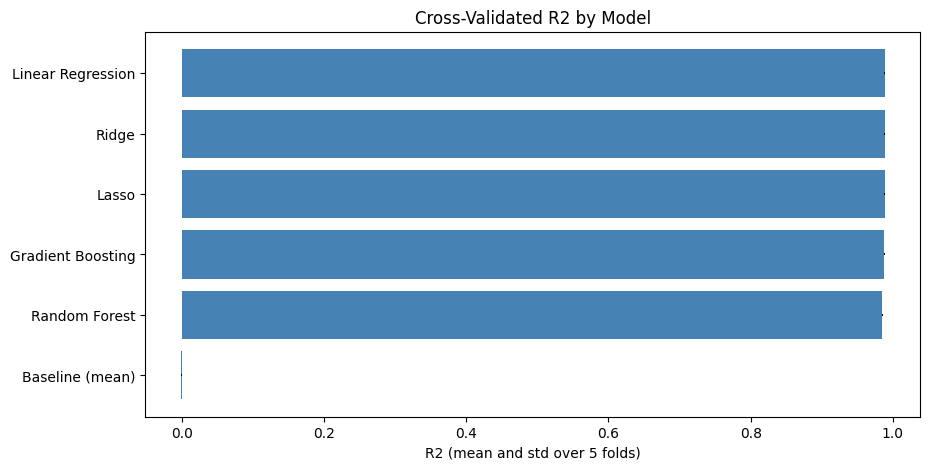

In [38]:
# Cross-Validated R2 by Model
plt.figure(figsize=(10, 5))
plt.barh(results.index[::-1], results["CV R2 (mean)"][::-1], xerr=results["CV R2 (std)"][::-1], color="steelblue")
plt.title("Cross-Validated R2 by Model")
plt.xlabel("R2 (mean and std over 5 folds)")
plt.show()

a higher R2 and a lower MAE / RMSE are better.

we can conclude that the best model for our data is multiple linear regression